In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/column_3C_weka.csv')

In [3]:
df.head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,Hernia
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Hernia
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,Hernia
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,Hernia
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Hernia


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    object 
dtypes: float64(6), object(1)
memory usage: 17.1+ KB


In [5]:
df['class'].value_counts()

class
Spondylolisthesis    150
Normal               100
Hernia                60
Name: count, dtype: int64

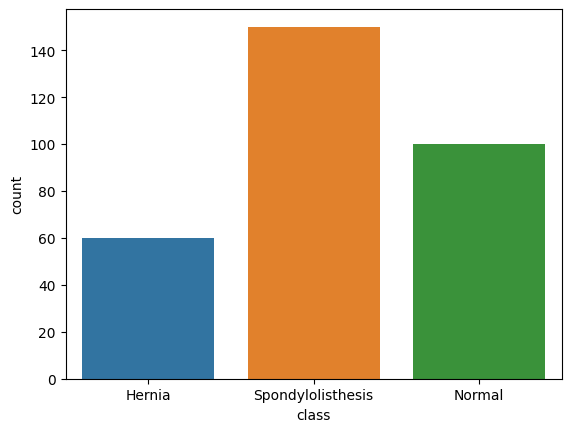

In [6]:
sns.countplot(x='class', data=df, hue='class');

In [7]:
df['class'] = df['class'].map({'Hernia': 1, 'Normal': 0, 'Spondylolisthesis': 2})

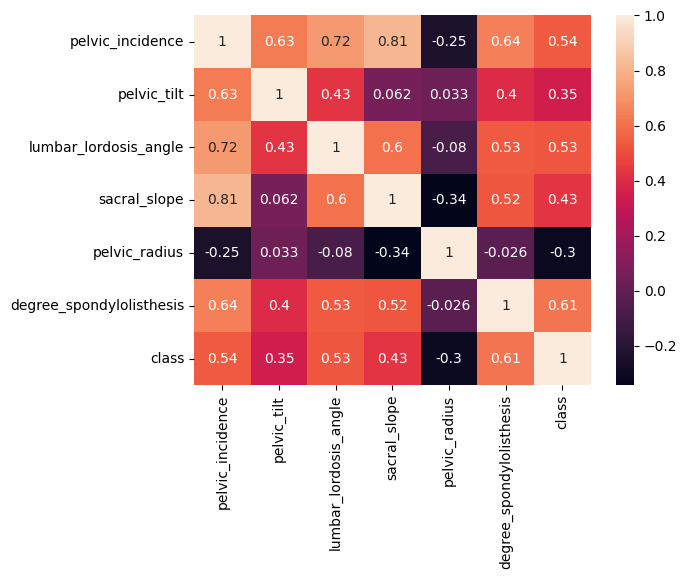

In [8]:
sns.heatmap(df.corr(), annot=True);

In [9]:
## Мы не используем Изоляционный Лес так как строк очень мало

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
from sklearn.impute import KNNImputer

In [11]:
X = df.drop('class', axis=1)

In [12]:
y = df['class']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104, stratify=y)

In [14]:
num_features = X_train.columns.tolist()

In [15]:
num_features

['pelvic_incidence',
 'pelvic_tilt',
 'lumbar_lordosis_angle',
 'sacral_slope',
 'pelvic_radius',
 'degree_spondylolisthesis']

In [16]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [18]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_jobs=-1))
])

In [19]:
param_grid = {
    'model__n_neighbors': range(3, 50, 2),
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
    'model__p': [1, 1.5, 2, 3]
}

In [20]:
grid_pipe = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    n_jobs=-1,
    cv=10
)

In [21]:
%%time
grid_pipe.fit(X_train, y_train)

CPU times: total: 3.53 s
Wall time: 16.3 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(3, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the comput

In [22]:
y_pred = grid_pipe.predict(X_test)
y_pred_proba = grid_pipe.predict_proba(X_test)
y_train_proba = grid_pipe.predict_proba(X_train)

In [23]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, average=None)
precision = precision_score(y_test, y_pred, average=None)

roc_auc_test = roc_auc_score(y_test, y_pred_proba, average=None, multi_class='ovr')
roc_auc_train = roc_auc_score(y_train, y_train_proba, average=None, multi_class='ovr')

In [24]:
best_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_knn.weights}")
print(f"  Формула расстояния (metric):      {best_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_knn.algorithm}")
print(f"                            P:      {best_knn.p}")

  Количество соседей (n_neighbors): 15
  Функция весов (weights):          uniform
  Формула расстояния (metric):      manhattan
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [25]:
accuracy

0.7096774193548387

In [26]:
recall

array([0.7       , 0.41666667, 0.83333333])

In [27]:
precision

array([0.53846154, 0.625     , 0.89285714])

In [28]:
roc_auc_train

array([0.92220982, 0.94640625, 0.98453776])

In [29]:
roc_auc_test

array([0.8672619 , 0.9375    , 0.93541667])

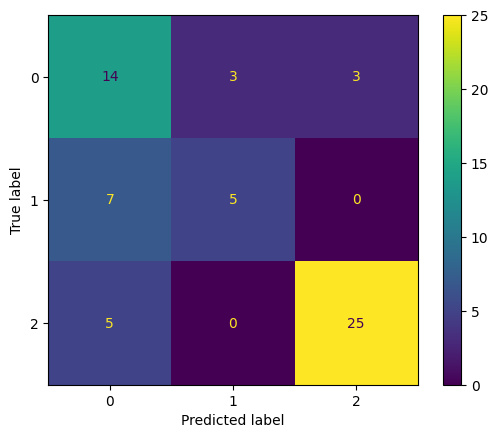

In [30]:
ConfusionMatrixDisplay.from_estimator(grid_pipe, X_test, y_test);

In [31]:
def plot_multiclass_roc(clf, X_test, y_test, n_classes, figsize=(5,5)):
    y_score = clf.predict_proba(X_test)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    y_test_dummies = pd.get_dummies(y_test, drop_first=False).values
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_dummies[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Receiver operating characteristic example')
    for i in range(n_classes):
        ax.plot(fpr[i], tpr[i], label='ROC curve (area = %0.2f) for label %i' % (roc_auc[i], i))
    ax.legend(loc="best")
    ax.grid(alpha=.4)
    sns.despine()
    plt.show()

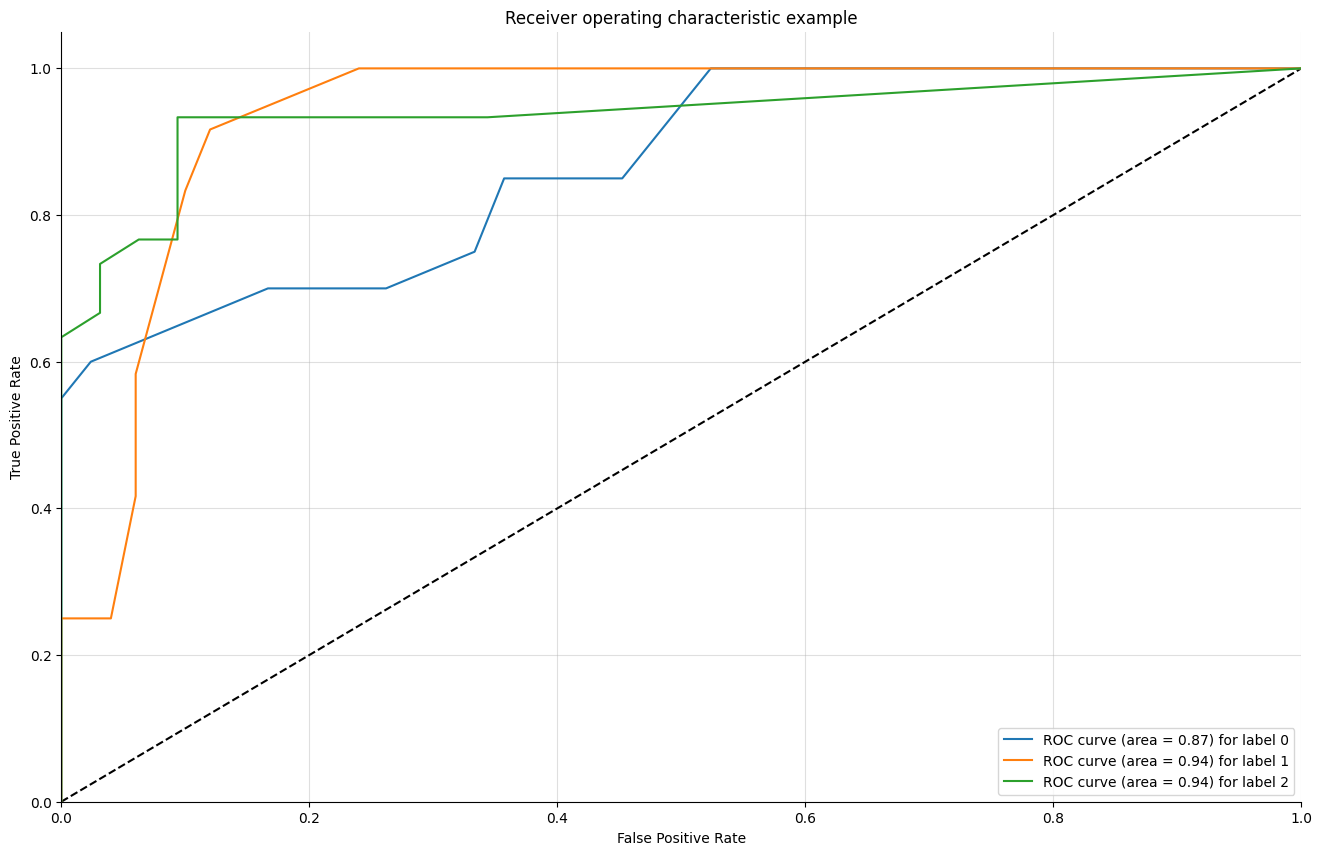

In [32]:
plot_multiclass_roc(grid_pipe, X_test, y_test, n_classes=3, figsize=(16, 10))

In [33]:
%%time
grid_pipe.fit(X, y)

CPU times: total: 2.95 s
Wall time: 9.3 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(3, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the comput

In [34]:
y_full_proba = grid_pipe.predict_proba(X)

In [35]:
best_final_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_final_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_final_knn.weights}")
print(f"  Формула расстояния (metric):      {best_final_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_final_knn.algorithm}")
print(f"                            P:      {best_final_knn.p}")

  Количество соседей (n_neighbors): 17
  Функция весов (weights):          distance
  Формула расстояния (metric):      manhattan
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [36]:
roc_auc_full = roc_auc_score(y, y_full_proba, average=None, multi_class='ovr')

In [37]:
roc_auc_full

array([1., 1., 1.])

In [38]:
df[df['class'] == 0].head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
210,38.505273,16.964297,35.112814,21.540976,127.632875,7.986683,0
211,54.920858,18.968430,51.601455,35.952428,125.846646,2.001642,0
212,44.362490,8.945435,46.902096,35.417055,129.220682,4.994195,0
213,48.318931,17.452121,48.000000,30.866809,128.980308,-0.910941,0
214,45.701789,10.659859,42.577846,35.041929,130.178314,-3.388910,0


In [39]:
df[df['class'] == 2].head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
60,74.377678,32.053104,78.772013,42.324573,143.560690,56.125906,2
61,89.680567,32.704435,83.130732,56.976132,129.955476,92.027277,2
62,44.529051,9.433234,52.000000,35.095817,134.711772,29.106575,2
63,77.690577,21.380645,64.429442,56.309932,114.818751,26.931841,2
64,76.147212,21.936186,82.961502,54.211027,123.932010,10.431972,2


In [40]:
spine_custom_profiles = {
    'pelvic_incidence':        [38.50027,           49.70786,            70.0], 
    'pelvic_tilt':             [16.96930,           9.64708,             27.0],
    'lumbar_lordosis_angle':   [35.11781,           28.31241,            75.0],
    'sacral_slope':            [21.53598,           40.05578,            46.0],
    'pelvic_radius':           [127.63788,          108.16373,           130.0],
    'degree_spondylolisthesis': [7.98188,            7.91350,             48.0]      
}

In [41]:
custom_spine_df = pd.DataFrame(spine_custom_profiles)

In [42]:
custom_spine_df

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
0,38.50027,16.96930,35.11781,21.53598,127.63788,7.98188
1,49.70786,9.64708,28.31241,40.05578,108.16373,7.91350
2,70.00000,27.00000,75.00000,46.00000,130.00000,48.00000


In [43]:
spine_preds = grid_pipe.best_estimator_.predict(custom_spine_df)
spine_probs = grid_pipe.best_estimator_.predict_proba(custom_spine_df)

In [44]:
spine_labels_map = {
    0: "🍏 ЗДОРОВЫЙ ПОЗВОНОЧНИК (Normal)",
    1: "🛑 МЕЖПОЗВОНОЧНАЯ ГРЫЖА ДИСКА (Disk Hernia)",
    2: "🚨 СМЕЩЕНИЕ ПОЗВОНКА (Spondylolisthesis)"
}

print("="*90)
print("🩺 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ПОЗВОНОЧНИКУ:")
print("="*90)

expected_diagnoses = [0, 1, 2]

for i, expected in enumerate(expected_classes if 'expected_classes' in locals() else expected_diagnoses):
    predicted_class = spine_preds[i]
    
    class_indices = list(grid_pipe.best_estimator_.classes_)
    pred_idx_in_proba = class_indices.index(predicted_class)
    confidence = spine_probs[i][pred_idx_in_proba] * 100
    
    print(f"Пациент №{i+1} (Ожидался класс {expected}):")
    print(f"  -> Диагноз модели: {spine_labels_map.get(predicted_class, 'Неизвестный тип')}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 90)

🩺 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ПОЗВОНОЧНИКУ:
Пациент №1 (Ожидался класс 0):
  -> Диагноз модели: 🍏 ЗДОРОВЫЙ ПОЗВОНОЧНИК (Normal)
  -> Уверенность модели: 98.87%
------------------------------------------------------------------------------------------
Пациент №2 (Ожидался класс 1):
  -> Диагноз модели: 🛑 МЕЖПОЗВОНОЧНАЯ ГРЫЖА ДИСКА (Disk Hernia)
  -> Уверенность модели: 99.16%
------------------------------------------------------------------------------------------
Пациент №3 (Ожидался класс 2):
  -> Диагноз модели: 🚨 СМЕЩЕНИЕ ПОЗВОНКА (Spondylolisthesis)
  -> Уверенность модели: 95.10%
------------------------------------------------------------------------------------------


In [45]:
class_percents = df['class'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%, 2: {class_percents[2]:.1f}%"
print(f"{baseline_string}")

0: 32.3%, 1: 19.4%, 2: 48.4%


In [46]:
import json
import os

advanced_report = {
    "project": "Spine Type Prediction",
    "model": "KNeighborsClassifier",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_knn.n_neighbors,
        "weights": best_knn.weights,
        "metric": best_knn.metric,
        "p": best_knn.p
    },
    "final_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_final_knn.n_neighbors,
        "weights": best_final_knn.weights,
        "metric": best_final_knn.metric,
        "p": best_final_knn.p
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": {
            "Normal": precision[0],
            "Hernia": precision[1],
            "Spondylolisthesis": precision[2]
        },
        "Recall Score": {
            "Normal": recall[0],
            "Hernia": recall[1],
            "Spondylolisthesis": recall[2]
        },
        "ROC AUC Score Train": {
            "Normal": roc_auc_train[0],
            "Hernia": roc_auc_train[1],
            "Spondylolisthesis": roc_auc_train[2]
        },
        "ROC AUC Score Test": {
            "Normal": roc_auc_test[0],
            "Hernia": roc_auc_test[1],
            "Spondylolisthesis": roc_auc_test[2]
        },
        "ROC AUC Score Full": {
            "Normal": roc_auc_full[0],
            "Hernia": roc_auc_full[1],
            "Spondylolisthesis": roc_auc_full[2]
        },
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [47]:
from joblib import dump, load

In [48]:
dump(grid_pipe, "model/spine_type_predict_k_neighbors_classifier_2026_v1.pkl")

['model/spine_type_predict_k_neighbors_classifier_2026_v1.pkl']

In [49]:
loaded_pipe = load("model/spine_type_predict_k_neighbors_classifier_2026_v1.pkl")

In [50]:
spine_preds = grid_pipe.best_estimator_.predict(custom_spine_df)
spine_probs = grid_pipe.best_estimator_.predict_proba(custom_spine_df)

In [51]:
spine_labels_map = {
    0: "🍏 ЗДОРОВЫЙ ПОЗВОНОЧНИК (Normal)",
    1: "🛑 МЕЖПОЗВОНОЧНАЯ ГРЫЖА ДИСКА (Disk Hernia)",
    2: "🚨 СМЕЩЕНИЕ ПОЗВОНКА (Spondylolisthesis)"
}

print("="*90)
print("🩺 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ПОЗВОНОЧНИКУ:")
print("="*90)

expected_diagnoses = [0, 1, 2]

for i, expected in enumerate(expected_classes if 'expected_classes' in locals() else expected_diagnoses):
    predicted_class = spine_preds[i]
    
    class_indices = list(grid_pipe.best_estimator_.classes_)
    pred_idx_in_proba = class_indices.index(predicted_class)
    confidence = spine_probs[i][pred_idx_in_proba] * 100
    
    print(f"Пациент №{i+1} (Ожидался класс {expected}):")
    print(f"  -> Диагноз модели: {spine_labels_map.get(predicted_class, 'Неизвестный тип')}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 90)

🩺 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ПОЗВОНОЧНИКУ:
Пациент №1 (Ожидался класс 0):
  -> Диагноз модели: 🍏 ЗДОРОВЫЙ ПОЗВОНОЧНИК (Normal)
  -> Уверенность модели: 98.87%
------------------------------------------------------------------------------------------
Пациент №2 (Ожидался класс 1):
  -> Диагноз модели: 🛑 МЕЖПОЗВОНОЧНАЯ ГРЫЖА ДИСКА (Disk Hernia)
  -> Уверенность модели: 99.16%
------------------------------------------------------------------------------------------
Пациент №3 (Ожидался класс 2):
  -> Диагноз модели: 🚨 СМЕЩЕНИЕ ПОЗВОНКА (Spondylolisthesis)
  -> Уверенность модели: 95.10%
------------------------------------------------------------------------------------------
